In [1]:
# Exploratory Data Analysis of ~2.2M synthetic (demo) real-estate property listings (realtor.com data, 1969-2022).
# Pipeline: clean data (types, duplicates, missing values) -> column statistics ->
# market analysis per state -> correlation/heatmap + distribution plots -> written insights.
# Run top-to-bottom: cell outputs feed the insight numbers in section 5.

import glob
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import numpy as np # linear algebra
import seaborn as sns

# Read file — the CSV is shipped split into <25 MB pieces (GitHub's per-file
# upload limit); every piece repeats the header, so globbing the parts and
# concatenating rebuilds exactly the single-CSV frame.
df = pd.concat([pd.read_csv(p) for p in sorted(glob.glob('data/realtor-data-synthetic-part-*.csv'))],
               ignore_index=True)

In [2]:
# 1. Data Cleaning
# 1.1. How many rows and columns in the data frame?
# 1.2. What does the data look like (top 10 rows)?
# 1.3. What are the column data types in the data frame?
# 1.4. Convert data types
# 1.5. What are the column data types in the data frame after converting data types?
# 1.6. Are there duplicates in the data frame?
# 1.7. Remove duplicates
# 1.8. Are there missing values in the data frame?
# 1.9. For the largest amount of missing values inpute mean values 

# 2. Data Statistics
# 2.1. Summarise columns in the data frame
# 2.2. What are the distribution of variables 'state'
# 2.3. What are the distribution of variables 'status'

# 3. Market Analysis
# 3.1. What is the relationships between 'state' and mean 'price'
# 3.1.1. Summary of the least expensive state
# 3.1.2. Summary of the most expensive state
# 3.2. What is the relationship between house features per state?
# 3.3 Filtering data
# 3.3.1. Plot the price of sold properties against the number of bedrooms
# 3.3.2. Plot the price of sold properties against the number of bathrooms
# 3.3.3. Plot the price of sold properties against the acre lot

# 4. Data Correlation
# 4.1 Correlation coefficient heatmap
# 4.2. Visualise correlations
# 4.3. Visualise histograms
# 4.4. Visualise data with their quartiles

# 5. Insights for Real Estate Property Listings


# **1. Data Cleaning**

In [3]:
# 1.1. How many rows and columns in the data frame?
df.shape

(2226382, 12)

In [4]:
# 1.2. What does the data look like (top 10 rows)?
df.head(10)

,state,city,brokered_by,status,price,bed,bath,acre_lot,street,zip_code,house_size,prev_sold_date
0,Region-01,Region-01-City-05,37266.0,sold,340570.0,3.0,2.0,0.11,1313910.0,33709.0,2128.0,2022-02-16
1,Region-01,Region-01-City-196,70605.0,sold,250000.0,NaN,2.0,0.16,1447028.0,33156.0,3734.0,2022-04-07
2,Region-01,Region-01-City-02,22530.0,for_sale,300000.0,3.0,NaN,0.23,1525255.0,32827.0,1121.0,2005-03-18
3,Region-01,Region-01-City-147,87932.0,for_sale,499900.0,NaN,1.0,NaN,1561553.0,33935.0,NaN,2014-04-15
4,Region-01,Region-01-City-06,84046.0,for_sale,165000.0,3.0,2.0,0.42,626698.0,32428.0,1887.0,2015-12-15
5,Region-01,Region-01-City-03,46815.0,for_sale,139000.0,3.0,NaN,0.39,1699243.0,32653.0,NaN,2022-04-04
6,Region-01,Region-01-City-08,64281.0,sold,385000.0,1.0,2.0,0.33,173122.0,34481.0,1666.0,2021-12-29
7,Region-01,Region-01-City-221,30690.0,for_sale,699900.0,2.0,3.0,0.13,1396583.0,32208.0,1056.0,2022-02-17
8,Region-01,Region-01-City-123,79629.0,sold,27000.0,2.0,2.0,1.77,1639376.0,33596.0,NaN,NaN
9,Region-01,Region-01-City-39,10428.0,for_sale,225900.0,NaN,3.0,NaN,1367278.0,33905.0,1232.0,2012-01-12


In [5]:
# 1.3. What are the column data types in the data frame?
df.dtypes

state                 str
city                  str
brokered_by       float64
status                str
price             float64
bed               float64
bath              float64
acre_lot          float64
street            float64
zip_code          float64
house_size        float64
prev_sold_date        str
dtype: object

In [6]:
# 1.4. Convert data types
df = df.convert_dtypes()
# Convert datetime  column
df['prev_sold_date'] = pd.to_datetime(df['prev_sold_date'], errors = 'coerce')
# Check types
df.dtypes

state                     string
city                      string
brokered_by                Int64
status                    string
price                    Float64
bed                        Int64
bath                       Int64
acre_lot                 Float64
street                     Int64
zip_code                   Int64
house_size                 Int64
prev_sold_date    datetime64[us]
dtype: object

In [7]:
# 1.5. What are the column data types in the data frame after converting data types?
df.head(10)

,state,city,brokered_by,status,price,bed,bath,acre_lot,street,zip_code,house_size,prev_sold_date
0,Region-01,Region-01-City-05,37266,sold,340570.0,3,2,0.11,1313910,33709,2128,2022-02-16
1,Region-01,Region-01-City-196,70605,sold,250000.0,<NA>,2,0.16,1447028,33156,3734,2022-04-07
2,Region-01,Region-01-City-02,22530,for_sale,300000.0,3,<NA>,0.23,1525255,32827,1121,2005-03-18
3,Region-01,Region-01-City-147,87932,for_sale,499900.0,<NA>,1,<NA>,1561553,33935,<NA>,2014-04-15
4,Region-01,Region-01-City-06,84046,for_sale,165000.0,3,2,0.42,626698,32428,1887,2015-12-15
5,Region-01,Region-01-City-03,46815,for_sale,139000.0,3,<NA>,0.39,1699243,32653,<NA>,2022-04-04
6,Region-01,Region-01-City-08,64281,sold,385000.0,1,2,0.33,173122,34481,1666,2021-12-29
7,Region-01,Region-01-City-221,30690,for_sale,699900.0,2,3,0.13,1396583,32208,1056,2022-02-17
8,Region-01,Region-01-City-123,79629,sold,27000.0,2,2,1.77,1639376,33596,<NA>,NaT
9,Region-01,Region-01-City-39,10428,for_sale,225900.0,<NA>,3,<NA>,1367278,33905,1232,2012-01-12


In [8]:
# 1.6. Are there duplicates in the data frame?
df.duplicated().sum()

np.int64(0)

In [9]:
# 1.7. Remove duplicates
df.drop_duplicates(inplace = True)

In [10]:
# 1.8 Are there missing values in the data frame?
df.isnull().sum()

state                  0
city                1407
brokered_by         4533
status                 0
price               1541
bed               481317
bath              511771
acre_lot          325589
street             10866
zip_code             299
house_size        568484
prev_sold_date    734297
dtype: int64

In [11]:
# 1.9 For the largest amount of missing values inpute mean values 
# Populate NaN values with mean value for 'bed', 'bath', 'acre_lot' and 'house_size'
df['bed'] = df['bed'].fillna(df['bed'].mean().round())
df['bath'] = df['bath'].fillna(df['bath'].mean().round())
df['acre_lot'] = df['acre_lot'].fillna(df['acre_lot'].mean().round())
df['house_size'] = df['house_size'].fillna(df['house_size'].mean().round())
df['price'] = df['price'].fillna(df['price'].mean().round())
df['prev_sold_date'] = df['prev_sold_date'].fillna(pd.NaT) 

In [12]:
# 1.10 Check for missing values in the data frame.
df.isnull().sum()

state                  0
city                1407
brokered_by         4533
status                 0
price                  0
bed                    0
bath                   0
acre_lot               0
street             10866
zip_code             299
house_size             0
prev_sold_date    734297
dtype: int64

# **2. Data Statistics**

In [13]:
# 2.1. Summarise columns in the data frame
df[['bed', 'bath', 'acre_lot', 'house_size', 'price']].describe()

,bed,bath,acre_lot,house_size,price
count,2226382.0,2226382.0,2226382.0,2226382.0,2226382.0
mean,3.216808,2.383467,14.812206,2100.774545,525272.943873
std,1.444812,1.567689,670.958426,17501.66143,2744580.153546
min,1.0,1.0,0.0,4.0,0.0
25%,3.0,2.0,0.17,1456.0,165000.0
50%,3.0,2.0,0.35,2101.0,325000.0
75%,4.0,3.0,3.48,2140.0,550000.0
max,473.0,830.0,100000.0,12992200.0,2147483600.0


In [14]:
# 2.2. What are the distribution of variables
# 'state'?
df['state'].value_counts(ascending = True)

state
Region-56         1
Region-55         8
Region-54       489
Region-53       895
Region-52      2581
Region-51      2600
Region-50      3126
Region-49      3642
Region-48      4039
Region-47      4268
Region-46      4690
Region-45      5065
Region-44      6309
Region-43      6625
Region-42      7243
Region-41      8157
Region-40      8628
Region-39     10059
Region-38     12309
Region-37     14008
Region-36     14557
Region-35     14667
Region-34     14858
Region-33     16255
Region-32     16760
Region-31     18840
Region-30     21074
Region-29     23033
Region-28     23045
Region-27     25815
Region-26     26316
Region-25     32163
Region-24     32293
Region-23     34053
Region-22     37140
Region-21     38041
Region-20     40964
Region-19     42367
Region-18     42390
Region-17     42429
Region-16     43412
Region-15     45145
Region-14     46052
Region-13     48199
Region-12     59207
Region-11     62461
Region-10     68763
Region-09     72825
Region-08     78373
Region-07     

In [15]:
# 2.3. What are the distribution of variables
# 'status'?
df['status'].value_counts(ascending = True)

status
ready_to_build      25224
sold               812606
for_sale          1388552
Name: count, dtype: Int64

# **3. Market Analysis**

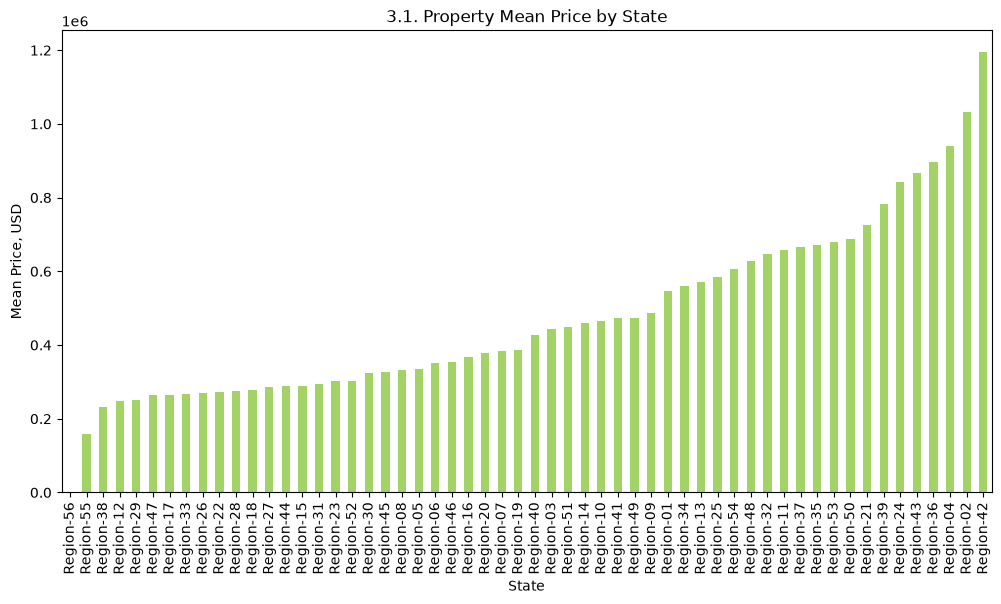

In [16]:
# 3.1. What is the relationships between 'state' and mean 'price'
mean_price_per_state = df.groupby('state')['price'].mean().sort_values()

plt.figure(figsize = (12, 6))
mean_price_per_state.plot(kind = 'bar', color = '#a3d266')
plt.title('3.1. Property Mean Price by State')
plt.xlabel('State')
plt.ylabel('Mean Price, USD')
plt.show()

In [17]:
# 3.1.1. Summary of the least expensive state
state_min_price = df[df['state'] == 'Region-56']
state_min_price.describe()

,brokered_by,price,bed,bath,acre_lot,street,zip_code,house_size,prev_sold_date
count,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1
mean,34080.0,2500.0,3.0,2.0,0.1,1800293.0,30125.0,2101.0,2021-08-06 00:00:00
min,34080.0,2500.0,3.0,2.0,0.1,1800293.0,30125.0,2101.0,2021-08-06 00:00:00
25%,34080.0,2500.0,3.0,2.0,0.1,1800293.0,30125.0,2101.0,2021-08-06 00:00:00
50%,34080.0,2500.0,3.0,2.0,0.1,1800293.0,30125.0,2101.0,2021-08-06 00:00:00
75%,34080.0,2500.0,3.0,2.0,0.1,1800293.0,30125.0,2101.0,2021-08-06 00:00:00
max,34080.0,2500.0,3.0,2.0,0.1,1800293.0,30125.0,2101.0,2021-08-06 00:00:00
std,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN


In [18]:
# 3.1.2. Summary of the most expensive state
state_max_price = df[df['state'] == 'Region-42']
state_max_price.describe()

,brokered_by,price,bed,bath,acre_lot,street,zip_code,house_size,prev_sold_date
count,7235.0,7243.0,7243.0,7243.0,7243.0,7213.0,7243.0,7243.0,4059
mean,50692.789496,1193897.911777,2.821483,2.216347,6.132763,1200201.629558,96770.885821,4959.314511,2010-10-03 19:36:03.192904
min,377.0,1.0,1.0,1.0,0.02,1043.0,96701.0,116.0,1969-10-01 00:00:00
25%,23592.0,320000.0,2.0,2.0,0.26,615458.0,96743.0,890.0,2005-02-04 00:00:00
50%,46725.0,650000.0,3.0,2.0,1.03,1302841.0,96771.0,1536.0,2014-06-27 00:00:00
75%,70602.0,1195000.0,3.0,2.0,9.145,1785066.0,96813.0,2101.0,2019-01-07 00:00:00
max,109978.0,79000000.0,19.0,113.0,1834.0,1996695.0,96826.0,927828.0,2022-06-10 00:00:00
std,29088.787694,2445097.772059,1.286289,2.538246,24.90299,614570.627602,36.088109,46539.796615,NaN


In [19]:
# 3.2. What is the relationship between house features per state?
# 'state', 'bed', 'bath', house_size' and 'price'
features_per_state = round(df.pivot_table(index = 'state',
                     values = ['bed','bath','acre_lot','house_size','price'],
                     aggfunc = 'mean'),1)
features_per_state.head(10)

,acre_lot,bath,bed,house_size,price
state,,,,,
Region-01,9.5,2.3,3.0,1883.3,547808.9
Region-02,24.6,2.5,3.2,1953.1,1032713.2
Region-03,9.9,2.5,3.3,2282.3,443999.4
Region-04,56.0,2.3,3.2,2013.7,940162.0
Region-05,10.5,2.4,3.1,2077.4,335554.1
Region-06,6.0,2.3,3.1,1973.9,350355.5
Region-07,31.1,2.6,3.4,2241.5,385168.9
Region-08,5.3,2.3,3.3,2060.9,331756.4
Region-09,6.9,2.3,3.1,1979.2,486691.1


In [20]:
# 3.3. Filtered data for exploring
# Status is Sold, State is Region-23,
# Number of bedrooms is less than or equal to 5,
# Number of bathrooms is less than or eaul to4,
# Acre Lot is less than 1000,
# Price is less than USD 2000 000

# Filter data for specified criteria
filtered_data = df[(df['status'] == 'sold') &
                   (df['state'] == 'Region-23') &
                   (df['bed'] <= 5) &
                   (df['bath'] <= 4) &
                   (df['acre_lot'] <= 1000)&
                   (df['price'] <= 2000000)]

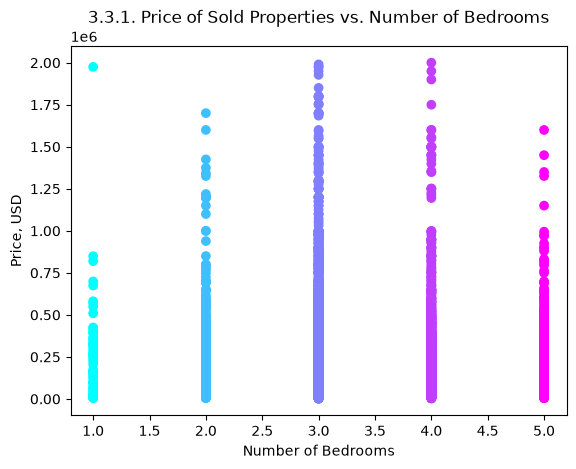

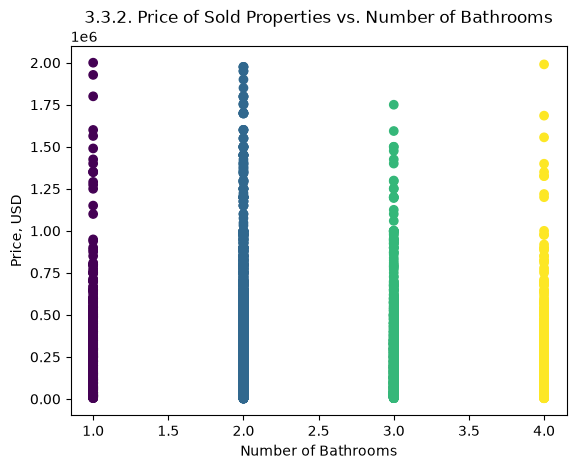

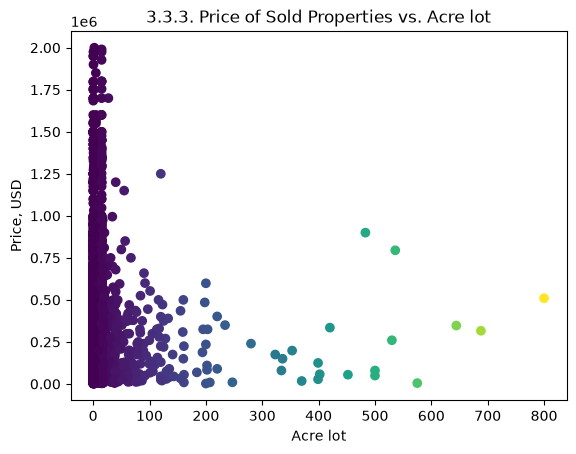

In [21]:
# 3.3.1. Plot the price of sold properties against the number of bedrooms
plt.scatter(filtered_data['bed'], filtered_data['price'], c = filtered_data['bed'], cmap = 'cool')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price, USD')
plt.title('3.3.1. Price of Sold Properties vs. Number of Bedrooms')
plt.show()

# 3.3.2. Plot the price of sold properties against the number of bathrooms
plt.scatter(filtered_data['bath'], filtered_data['price'], c = filtered_data['bath'], cmap = 'viridis')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price, USD')
plt.title('3.3.2. Price of Sold Properties vs. Number of Bathrooms')
plt.show()

# 3.3.3. Plot the price of sold properties against the acre lot
plt.scatter(filtered_data['acre_lot'], filtered_data['price'], c = filtered_data['acre_lot'], cmap = 'viridis')
plt.xlabel('Acre lot')
plt.ylabel('Price, USD')
plt.title('3.3.3. Price of Sold Properties vs. Acre lot')
plt.show()

# **4. Data Correlation**
Filtered Data

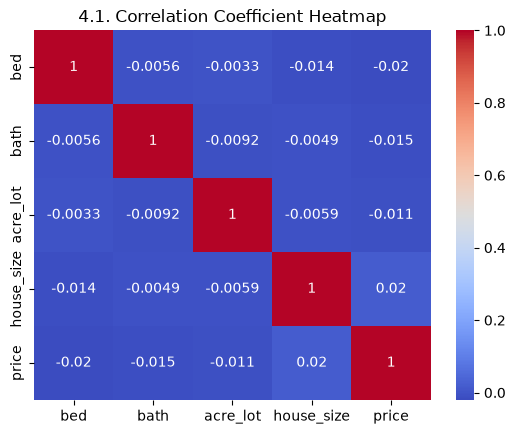

In [22]:
# 4.1 Correlation coefficient heatmap
# Are there any correlations in 'bath, 'bed', 'acre_lot', 'house_size' and 'price'?
correlation_data = filtered_data[['bed', 'bath', 'acre_lot', 'house_size','price']].corr(numeric_only = True)
sns.heatmap(correlation_data, cmap = 'coolwarm', annot = True)
plt.title("4.1. Correlation Coefficient Heatmap")
plt.show()

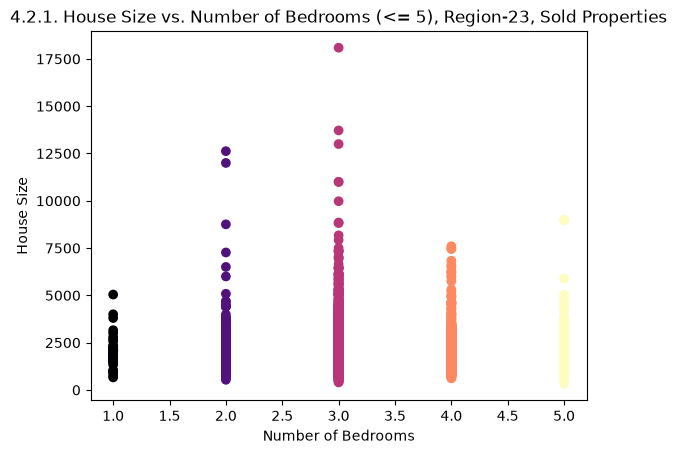

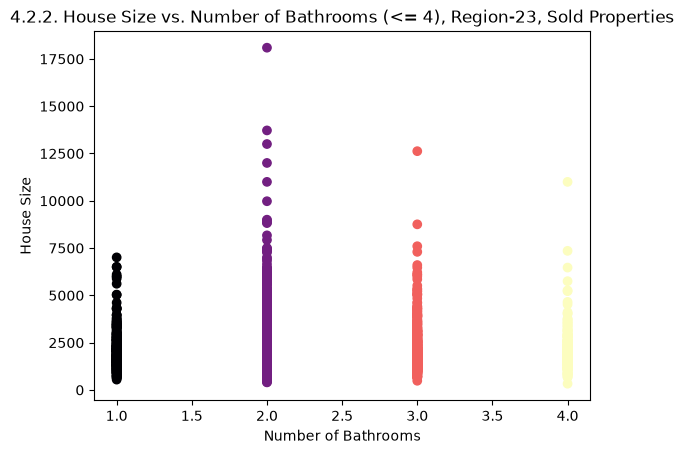

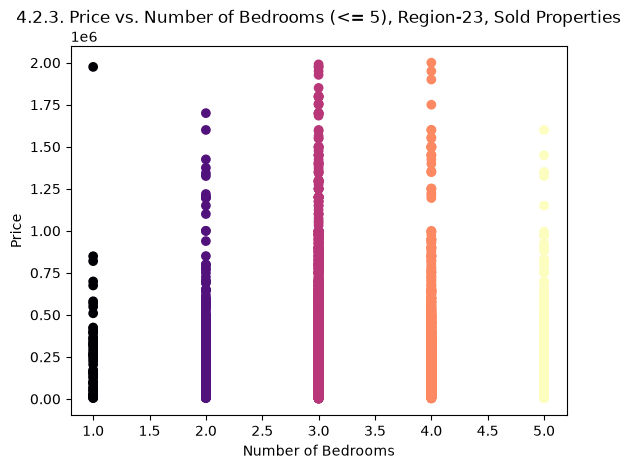

In [23]:
# 4.2. Visualise correlations
# 'house_size' and 'bed'
plt.scatter(filtered_data['bed'], filtered_data['house_size'], c=filtered_data['bed'], cmap='magma')
plt.xlabel('Number of Bedrooms')
plt.ylabel('House Size')
plt.title('4.2.1. House Size vs. Number of Bedrooms (<= 5), Region-23, Sold Properties')
plt.show()

# 'house_size' and 'bath'
plt.scatter(filtered_data['bath'], filtered_data['house_size'], c=filtered_data['bath'], cmap='magma')
plt.xlabel('Number of Bathrooms')
plt.ylabel('House Size')
plt.title('4.2.2. House Size vs. Number of Bathrooms (<= 4), Region-23, Sold Properties')
plt.show()

# 'bed' and 'price'
plt.scatter(filtered_data['bed'], filtered_data['price'], c=filtered_data['bed'], cmap='magma')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price')
plt.title('4.2.3. Price vs. Number of Bedrooms (<= 5), Region-23, Sold Properties')
plt.show()

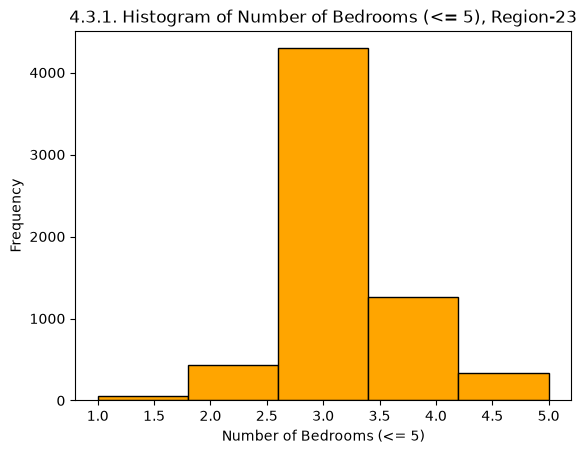

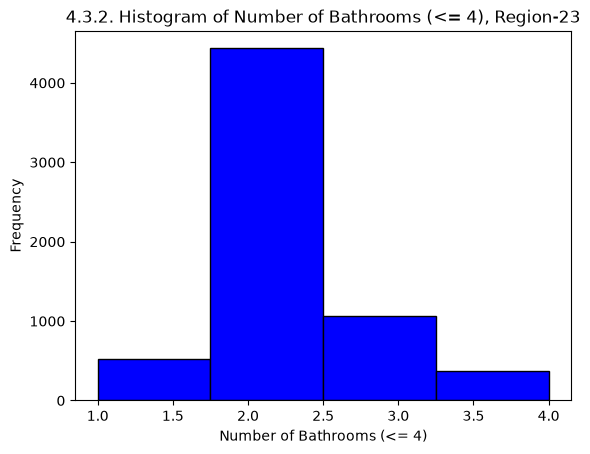

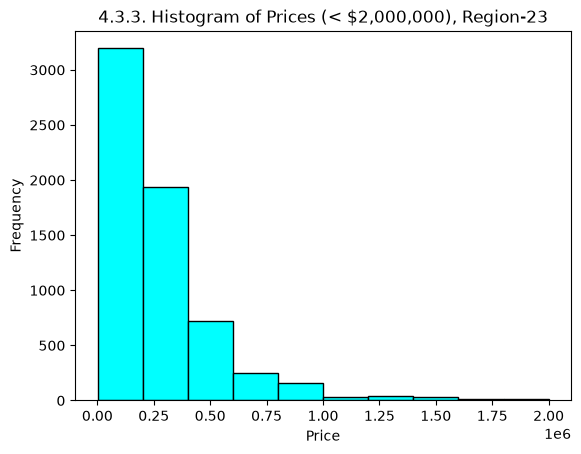

In [24]:
# 4.3. Visualise histograms
# 'bed' variable
plt.hist(filtered_data['bed'], bins=5, color='orange', edgecolor='black')
plt.xlabel('Number of Bedrooms (<= 5)')
plt.ylabel('Frequency')
plt.title('4.3.1. Histogram of Number of Bedrooms (<= 5), Region-23')
plt.show()

# 'bath' variable
plt.hist(filtered_data['bath'], bins=4, color='blue', edgecolor='black')
plt.xlabel('Number of Bathrooms (<= 4)')
plt.ylabel('Frequency')
plt.title('4.3.2. Histogram of Number of Bathrooms (<= 4), Region-23')
plt.show()

# 'price' variable
plt.hist(filtered_data['price'], bins=10, color='cyan', edgecolor='black')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('4.3.3. Histogram of Prices (< $2,000,000), Region-23')
plt.show()

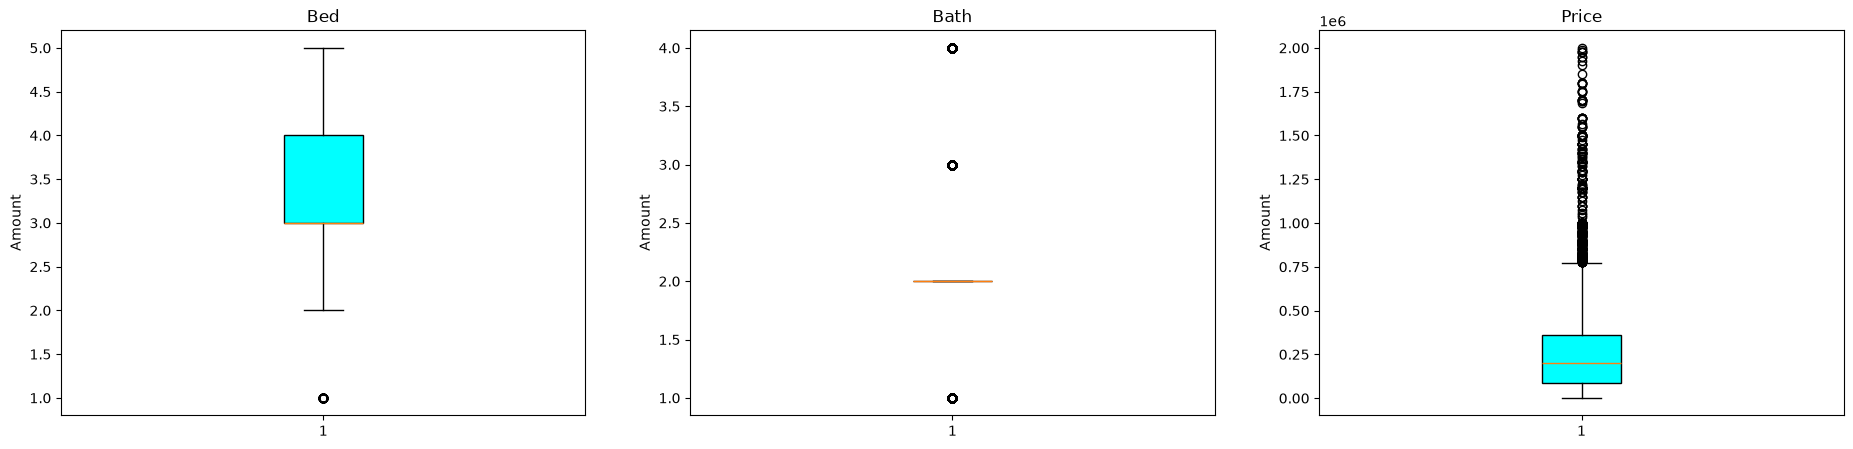

In [25]:
# 4.4. Visualise data with their quartiles
cols = ['bed', 'bath', 'price']

# Create a boxplot for each column
fig, axs = plt.subplots(1, len(cols), figsize=(23, 5))
for i, col in enumerate(cols):
    axs[i].boxplot(filtered_data[col], patch_artist=True, boxprops=dict(facecolor='cyan', color='black'))
    axs[i].set_title(col.capitalize())
    axs[i].set_ylabel('Amount')
plt.show()

# **5. Insights for Real Estate Property Listings**
All listed properties for all regions

Two different statistical bases are used below — label each claim so nobody
re-derives it on the wrong one: **whole dataset** (2 226 382 rows after dedupe,
mean-imputed) vs **filter slice** (6 391 rows, defined in {3.3}).

* Whole dataset: region with most listed properties is Region-01 (249 432 — the largest bucket). **{2.2}**
* Whole dataset: highest **mean** price is Region-42 (mean USD 1 193 898 over 7 243 listings); lowest mean price is Region-56 (mean USD 2 500 — its single listing, status for_sale). Phrase it as mean price, NOT "most/least listed properties": Region-01 alone has 249 432 listings, so Region-42 is only price-extreme, not volume-extreme. **{3.1}**
* Filter slice: sold properties in Region-23 with bedrooms ≤ 5, bathrooms ≤ 4, acre lot ≤ 1000, price ≤ USD 2 000 000 → 6 391 rows (the cells and their comments all use ≤, not <). **{3.3}**
* Within the slice: no correlation between house size and number of bedrooms (-0.01) or bathrooms (0.00). On the whole dataset the correlations are even closer to 0.00, so the conclusion holds either way — but quote the slice numbers only for the slice. **{4.1}**
* Slice-only: max prices of 2- and 5-bedroom properties similar (up to USD 1 700 000 / 1 600 000). On the whole dataset the maxima are 10-digit outliers (1e9 and 1e8), so this claim does NOT generalize. **{3.3.1}**
* Slice-only: modal acre lot is 15 with price up to USD 1 990 000 — only 1 571 of 6 391 rows ≈ 25%, so say **modal value**, never "majority". Whole-dataset modal acre lot is 0.17, which would contradict this claim if quoted globally. **{3.3.3}**
* Slice-only: most sold properties have 3 bedrooms (4 294), then 4 bedrooms (1 264). Whole-dataset modus is also 3 beds but with 752 263 rows — don't quote slice counts as global counts. **{4.3}**
* Slice-only: 2 baths most common (4 433); whole dataset modus is also 2 baths (745 343). **{4.3.2}**
* Slice-only: most common combination 3 beds / 2 baths (2 983 listings), median price USD 207 500. **{4.4}**
